# Exercise 3 - Neutrino Oscillation Fit
**2889683m**

In [2]:
# Import the required libraries for this exercise
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar

## Aims

The aims of the experiment are as follows:
- Write some simple fucntions that can calculate the probaility of the survival of a neutrino, and investiagte the behaviour of the probability when certain factors are changed
- Read in neutrino data from an external file and sort and plot this data as a histogram
- Use a $\chi^2$ function to fit this data and find a best fit value for the amplitude
- Obtain an error on this best fit value and compare it to the official RENO data

In this exercise, we will be working with the following probability equation (describes the survival probability of a neutrino to remain as $\bar{\nu}_e$):

$$ P(\bar\nu_e \rightarrow \bar\nu_e) = P_\mathrm{e\rightarrow e} = 1 - \sin^2 \! {2\theta} ~ \sin^2 \! \Big({1.267 \cdot \frac{\Delta m^2 L}{E}} \Big)$$


(where the $1.267$ is the appropriate numerical factor if $L$ is in meters, $E$ in MeV, and $\Delta m^2$ in eV<sup>2</sup>/c<sup>4</sup>)

$\theta$ is the angle between the two quantum eigenstates that make up the neutrinos, $\Delta m$ is the difference in the masses of the two neutrinos, $L$ is the distance separating them, and $E$ is their energy.

### Checking my Understanding

Taking the substitution $$z = \frac{1.267 \Delta m^2 L}{E} $$ the following can be said about the probability function:
1) When $z$ is small, the $sin$ term tends to 0, meaning the probability function tends to 1.
2) When $z = \frac{\pi}{2}$, $\pi$, $\frac{3\pi}{2}$, where the $sin$ term tends to 1, 0 and 1 repsectvely, meaning the probability function tends to $1-\sin^2{2\theta}$ (minimum), 1 (maximum) and $1-\sin^2{2\theta}$ respectively.
3) $P_{max}$ = 1 and $P_{min} = 1 - \sin^2{2\theta}$, so the maximum-to-minimum amplitude is $P_{max} - P_{min} = \sin^2{2\theta}$
4) If we rewrite the function in terms of $E$, we get the following:
   $$ P_{ee}(E) = 1 - \sin^2{2\theta}\sin^2{x[E]}$$
   Where $x[E] = 1.267\frac{\Delta m^2 L}{E}$ is a function of energy. The amplitude of this remains unchanged, as the $\sin^2{x[E]}$ will always only be between 0 and 1.

## Part 0 - Functions and Vectors

Because we are going to be working the neutrino probability function a lot in this exercise, it makes sense to define a function which can calculate it, and test it out by making some plots. This can be seen in the cell below:

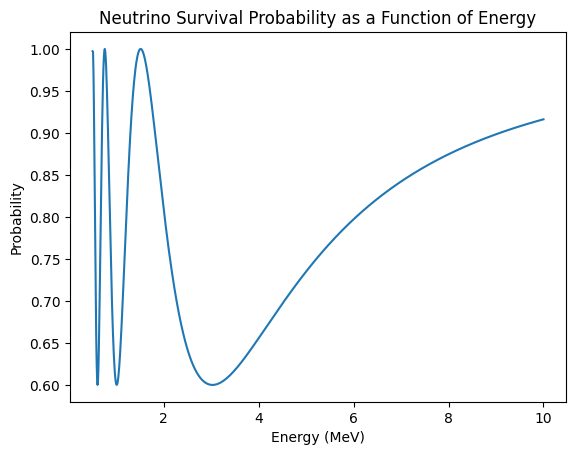

Figure 1: The neutrino survival probability as a function of energy.


In [3]:
# Define the function which will be sued to calculate the neutrino survival probability
def prob(E, A, L, dm):
    return 1 - A*np.sin(1.267*((dm*L)/E))**2

# Define the default arguments
A = 0.4
L = 1400
dm = (2.68e-3)

# Generate energy values between 0.5 and 10
E = np.linspace(0.5, 10, 1000)

# Run the function on the generated energy values to calculate the probability
Pe = prob(E, A, L, dm)

# Plot the results
plt.plot(E, Pe)
plt.title("Neutrino Survival Probability as a Function of Energy")
plt.xlabel("Energy (MeV)")
plt.ylabel("Probability")
plt.show()
print("Figure 1: The neutrino survival probability as a function of energy.")

As can be seen in Figure 1, the probability fucntion displays the expected behavior - it oscillates between 0.6 and 1, and at higher energies the oscillations get smoother and slower - this is because the argument of the second $\sin$ term becomes smaller, causing the oscillations to become slower and less pronounced, as it approaches a more stable value.

We now investigate the effect of changing the $\Delta m^2$ and $\sin^2{2\theta}$ values. In order to make it easier to see the effect of changing these values, they are only altered by $\sim 10$%. The plots can be seen below:

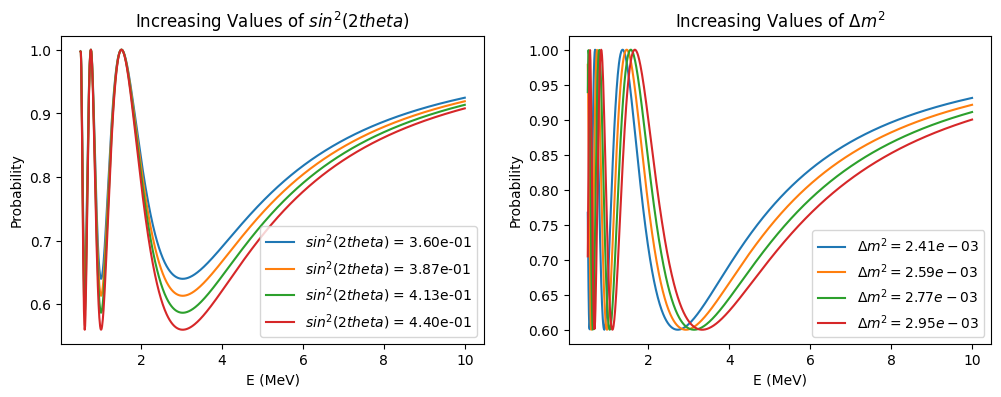

Figure 2: The probability-energy graphs for increasing values of sin^2(2theta) (left) and increasing values of dm^2.


In [4]:
# Use a linspace to generate values within 10% of the initial dm and sin^2(2theta) values
dms = np.linspace(dm-0.1*dm, dm+0.1*dm, 4)
As = np.linspace(A-0.1*A, A+0.1*A, 4)

# Define the figure size
plt.figure(figsize=(12,4))

# Use a loop to calculate the probability at each different A and dm value and plot it as a function of E
for x in range(len(dms)):
    Pe1 = prob(E, As[x], L, dm)
    Pe2 = prob(E, A, L, dms[x])
    plt.subplot(1,2,1)
    plt.plot(E, Pe1, label = f"$sin^2(2theta)$ = {As[x]:.2e}")
    plt.title(f"Increasing Values of $sin^2(2theta)$")
    plt.xlabel("E (MeV)")
    plt.ylabel("Probability")
    plt.legend()
    plt.subplot(1,2,2)
    plt.plot(E, Pe2, label = f"$\Delta m^2 = {dms[x]:.2e}$")
    plt.title(f"Increasing Values of $\Delta m^2$")
    plt.ylabel("Probability")
    plt.xlabel("E (MeV)")
    plt.legend()

plt.show()
print("Figure 2: The probability-energy graphs for increasing values of sin^2(2theta) (left) and increasing values of dm^2.")

As can be seen in the left graph of Figure 2, increasing the value of $\sin^2{2\theta}$ causes the mimima to become deeper, and the high energy asymptote move downward. This is because this term dictates the amplitude (as seen in the previous section).

Also seen in the right graph of Figure 2 is that increasing the value of $\Delta m^2$ shifts the oscillation features to higher energy and slightly increases the oscillation frequency. This is because $\Delta m^2$ appears inside the second $\sin^2$ term, and as long as $L$ remains fixed, increasing $\Delta m^2$ causes the oscillation extrema to occur at larger $E$, and makes the argument of the $\sin^2$ vary faster with E.

So, when the RENO experimenters are looking at the data to tell them about the two parameters $\Delta m^2$ and $\sin^2(2\theta)$, they will be looking at the energy position of the oscillation dip for information on $\Delta m^2$, and at the depth of the dip for information on $\sin^2{2\theta}$.

## Part 1 - Reading the Data

In order to analyse the RENO data, it must be read in from a file. This is done using `np.loadtxt` supplying the filepath, and then sorting the columns into their respective arrays. The columns are as follows:
1) `EMin` - The start of an energy range
2) `EMax` - The end of an energy range
3) `Data` - The number of candidate events registered in the far detector.
4) `DataErr` - The error on the data
5) `PredNoOsc` - The predicted number of events if no oscillations occurred.

This is done below, with the original file displayed in order to check the columns have been sorted properly.

In [5]:
# Load the file using np.loadtxt
data = np.loadtxt("/data/examples/p3/itlab/neutrino/reno.dat")

# Sort the data into the appropriate arrays
Emin = data[:,0]
Emax = data[:,1]
Data = data[:,2]
Dataerr = data[:,3]
Prednoosc = data[:,4]

# Define some useful quantities that may be required later in the code
Ecentre = np.array([(Emin+Emax)/2]) # The centre points of the energy 
Ewidth = np.array([Emax - Emin])

# Print the file and arrays to compare
print("Actual File:")
with open("/data/examples/p3/itlab/neutrino/reno.dat") as f:
    print(f.read())

print("Manually Sorted Columns:")
print("EMin     EMax     Data     DataErr     PredNoOsc")
for x in range(len(Emin)):
    print(f"{Emin[x]},     {Emax[x]},     {Data[x]},     {Dataerr[x]},     {Prednoosc[x]}")

Actual File:
#Comparison of the observed IBD prompt energy spectrum in the far site with no-oscillation prediction spectrum from the measurement in the near site.
#Figure 2 of "Measurement of Reactor Antineutrino Oscillation Amplitude and Frequency at RENO"
#
#Emin-max:   bin range in prompt reconstructed energy [MeV]
#Data:       number of observed IBD candidate events after background subtraction in the far detector
#DataErr:    error on Data
#PredNoOsc:	 number of predicted events from no oscillation
#
#EMin  EMax    Data  DataErr  PredNoOsc
1.20  1.40	2169.7	   59.5		2274.4
1.40  1.60	2890.5	   66.2		3120.8
1.60  1.80	3559.6	   71.5		3929.4
1.80  2.00	4297.5	   78.2		4615.0
2.00  2.20	4749.8	   81.0		5289.7
2.20  2.40	5260.4	   85.3		5770.6
2.40  2.60	5553.7	   79.7		6110.1
2.60  2.80	5775.6	   81.9		6339.0
2.80  3.00	5841.5	   81.5		6348.7
3.00  3.20	5701.0	   81.2		6282.9
3.20  3.40	5668.6	   79.7		6127.6
3.40  3.60	5376.0	   77.9		5756.0
3.60  3.80	5033.9	   75.7		5334.2
3.80  4

The sorted column arrays match perfectly with the original file columns. This indicates that the reading and sorting of the file has been successful.

## Part 2 - Making Some Plots

Now that the data has been properly read in, we will look at making some plots of it. 

A histogram is plotted for this dataset because particle-physics measurements are fundamentally “counts versus energy,” where each bin represents how many events were observed within a specific energy range. By dividing the energy axis into bins and assigning each event (or weighted event) to the correct bin, we reconstruct the underlying event-rate distribution that the experiment is measuring. In this task, the histogram of the predicted no-oscillation rate is created by first combining the lists of minimum and maximum bin edges into a single ordered edge list, then placing one weighted entry at the centre of each bin so that fractional predicted counts are handled correctly. The data points are then overlaid separately as both a histogram and as scatter points, along with the associated error bars. The marker positions are at the bin centres and x- and y-error bars representing the bin widths and the statistical uncertainties respectively. The plot can be seen below.

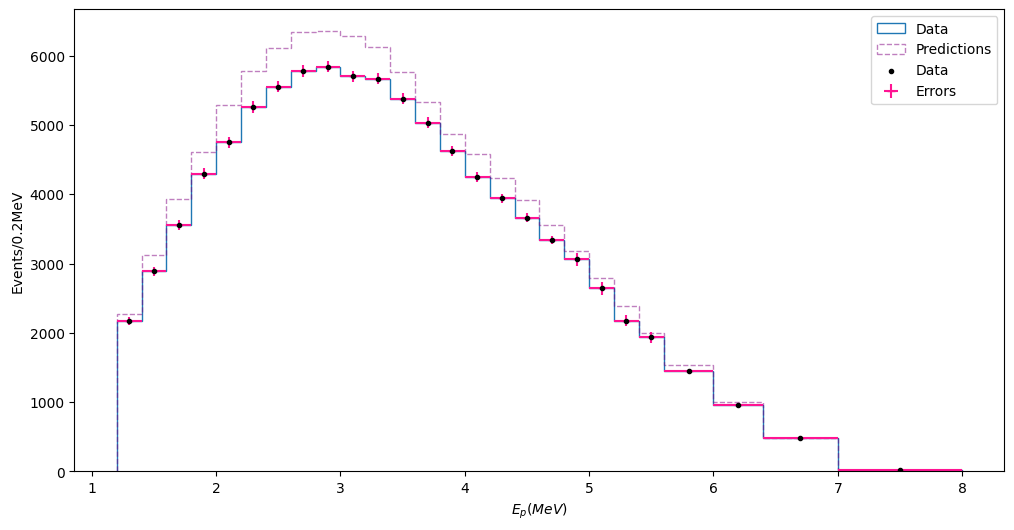

Figure 3: The histograms of the predicted no oscillations and the measured data with error bars.


In [6]:
# Combine the Emin and Emax arrays to create the bin edges
binedges = np.array([Emin[0]])
binedges = np.append(binedges, Emax)

# Define the bin widths for plotting
binwidths = np.diff(binedges)/2

plt.figure(figsize=(12,6))
# Plot the data as a histogram
plt.hist(binedges[:-1], binedges, weights = Data, label = "Data", histtype=u'step' )
plt.hist(binedges[:-1], binedges, weights = Prednoosc, alpha = 0.5, # Plot the predictions as a histogram
         label = "Predictions", histtype=u'step', ls = "--", color = "purple" )
plt.errorbar(binedges[:-1]+binwidths, Data, yerr = Dataerr, xerr = binwidths, # Plot the error bars
             fmt="_", color = "deeppink", label = "Errors")
plt.scatter(binedges[:-1]+binwidths, Data, marker = ".", label = "Data", # Plot the scattered data
            color = "black", zorder=10)
plt.xlabel(f"$E_p (MeV)$")
plt.ylabel(f"Events/0.2MeV")
plt.legend()
plt.show()
print(f"Figure 3: The histograms of the predicted no oscillations and the measured data with error bars.")

As can be seen in Figure 3, the plot shows the expected distribution of a smooth histogram, and is in good agreement with the plot from the RENO experiment (see Figure 4 below).

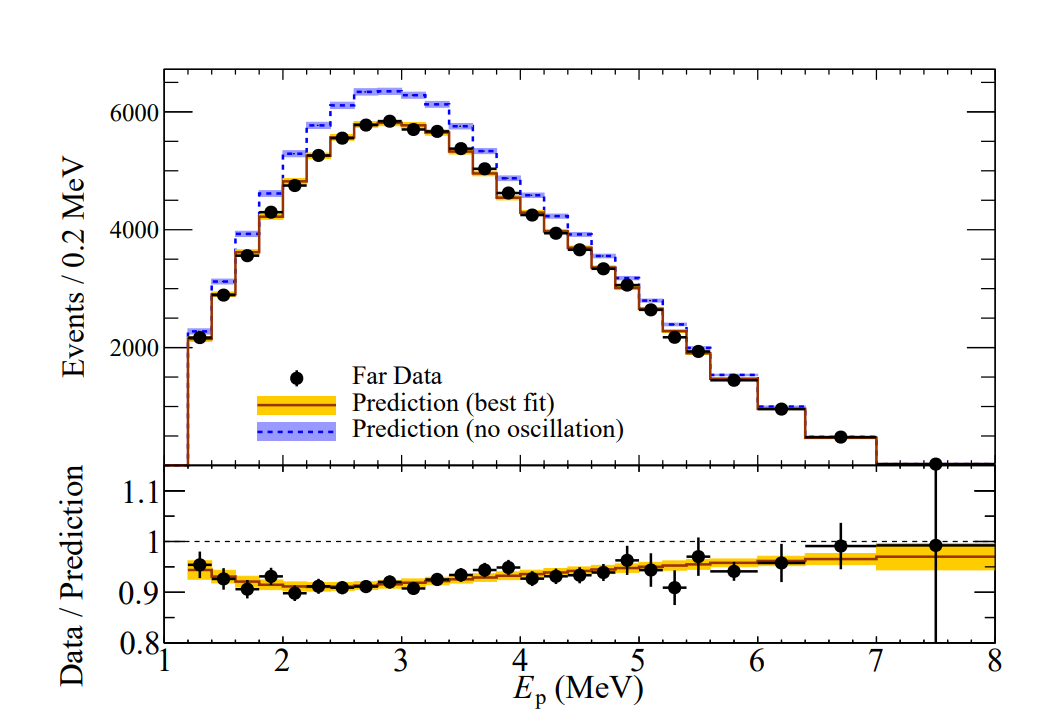

Figure 4: The experimental plot from the RENO experiment (picture taken from Bak et al.)

## Part 3 - Fitting the Data

Having plotted the data, we now look at finding a fit to it. In this exercise, we approach it as a minimisation problem, which requires an objective function to describe the difference between the model and the data. This objective function can be given by the $\chi^2$ function, which is as follows:

$$ \chi^2(x) = \sum_{i}^{n_{bins}} \frac{(D_i-M_i(x))^2}{\sigma_i^2} $$

where $D_i$ and $\sigma_i$ are the number of events in bin $i$ and its associated error, and $M_i(x)$ is the model prediction for the same bin.  We then define the model we described above: 

$$ M_i(\sin^2 2\theta) = P_{e\rightarrow e} (E_i;\sin^22\theta) \cdot O_i$$

where $O_i$ is the non-oscillated ("original") prediction.

This objective function can be minimised using the `minimize_scalar` function from the SciPy package, in order to obtain the best value of $\sin^2{2\theta}$.

Before performing the numerical fit, we can use the plotted data and prediction to estimate roughly what value of ($\sin^2{2\theta}$) should give good agreement. The peak in the data is smaller than the no-oscillation prediction, suggesting that the amplitude is below the maximum possible value of 1. By eye, a value of a couple tenths below 1 seems reasonable. 

On the other hand, any result outside the physical range ($0 \le \sin^2{2\theta} \le 1$) would be unphysical. This rough reasoning gives us a sense check for whether the fitted value produced by the code is reasonable.

The cell below uses the `minimise_scalar` function to find the best fit value of $\sin^2{2\theta}$, using the $\chi^2$ function as the objective function:

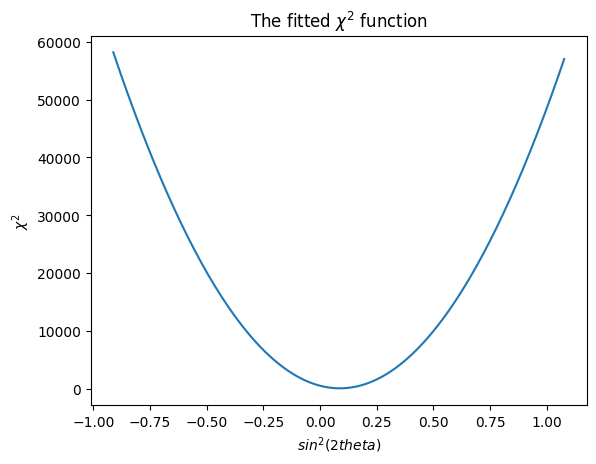

Figure 5: A plot of X^2 as a function of potential sin^2(2theta values)
The minimum amplitude value is = 0.08742


In [7]:
# Define the energy as the previously found centre points of the energy
E = Ecentre[0]

# Define a function to calculate the model prediction for the same bin
def Mi(E, A, O):
    # Use the same L and dm^2 values
    # Embedding these values in this functions minimises the chance of the wrong values being used
    L = 1400
    dm = 2.68e-3
    return prob(E, A, L, dm)*O

# Define a function to calculate X^2
def Xsq(A, Di, oi, E, O):
    Xs = 0
    for x in range(len(Di)): # Sum for each value in the dataset
        Xs = Xs +(((Di[x]-Mi(E[x], A, O[x]))**2)/oi[x]**2) 
    return Xs

# Run the minimise_scalar function
result = minimize_scalar(Xsq, args=(Data, Dataerr, E, Prednoosc))

# Sort the results into the appropriate arrays
scan_x = np.arange(result.x-1, result.x+1,0.01)  # Generate x values based on the minimum
scan_y = Xsq(scan_x, Data, Dataerr, E, Prednoosc)

# Plot the results
plt.plot(scan_x, scan_y)
plt.title(f"The fitted $\chi^2$ function")
plt.xlabel(f"$sin^2(2theta)$")
plt.ylabel(f"$\chi^2$")
plt.show()
print("Figure 5: A plot of X^2 as a function of potential sin^2(2theta values)")
print(f"The minimum amplitude value is = {result.x:.5f}")

The code has produced a best fit value of 0.08742 - this is in excellent agreement with the value obtained in the RENO experiment of $0.0874 \pm 0.005(stat) \pm 0.0054 (syst)$.

## Part 4 - The Fit Result

If the fit was perfect, we would have 
$$ D_i - P_{e\rightarrow e} (E_i) \cdot O_i = 0\\  \quad \Longrightarrow \quad  P_{e\rightarrow e} (E_i) = \frac{D_i}{O_i} $$

when we use our best fit value of $\sin^22\theta$. We can use this ratio to see how well the fit worked in practice.  

The cell below plots the ratio $\frac{D_i}{O_i}$ with the propagated error on this ratio (found by $\sigma_i = \frac{\sigma_D}{O_i}$). If the fit has went well, it should line up reasonably - though this fit won't be perfect, as there are only 26 data points being fitted. It should also be noted that the data won't match the fit quite so well at lower energies - this is due to the simplification of the fitter. The plot can be seen below:

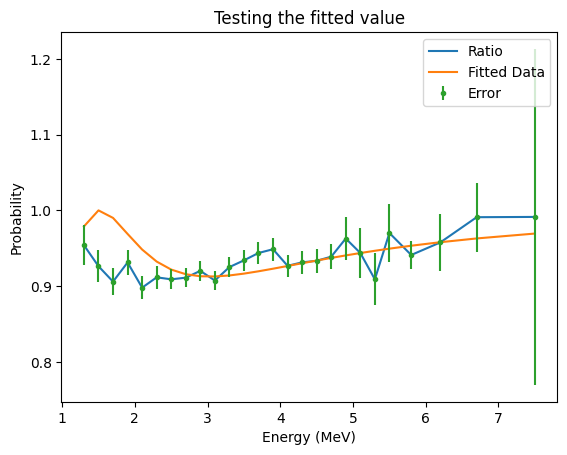

Figure 6: The plotted ratio along with the fitted data and associated errors.


In [8]:
# Assign the best fit value to a variable, and redefine L and dm
A = result.x
L = 1400
dm = 2.68e-3

# Plot the ratio
plt.plot(E, Data/Prednoosc, label = "Ratio")
plt.plot(E, prob(E, A, L, dm), label = "Fitted Data") # Plot the fitted data
plt.ylabel("Probability")
plt.xlabel("Energy (MeV)")
plt.title("Testing the fitted value")
plt.errorbar(E, Data/Prednoosc, yerr= Dataerr/Prednoosc, fmt=".", label = "Error") # Plot the errorbar
plt.legend()
plt.show()
print("Figure 6: The plotted ratio along with the fitted data and associated errors.")

As can be seen in Figure 6, while the plotted ratio graph is not a perfect fit (the irregularities can be attributed to the small number of data points being plotted), the graph shows a good general agreement with the fitted data - this is a positive indication that the fitted value is of reasonable accuracy.

The final part of this exercise is to find the error on the fitted $\sin^2{2\theta}$. This is done by plotting a graph of $\chi^2 - \chi^2_\text{min}$ against $\sin^22\theta$, and the two points where the function crosses the line $y=1$ are the edges of the error band, therefore the error is half the difference between them. The graph is plotted such that the y value only goes up to 4. The code below finds the error value on $\sin^2{2\theta}$:

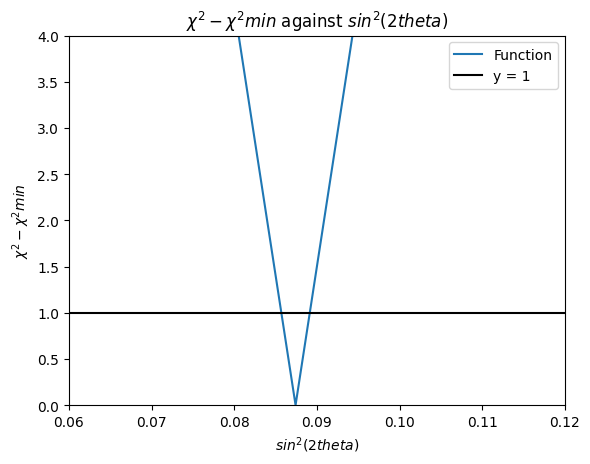

Figure 7: 
Amplitude error value = 0.08742 +/- 0.00172


In [9]:
# Define the values which will form the y axis (X^2 - X^2_{min})
y = scan_y-np.min(scan_y)

# Plot the graph within the specified limits
plt.plot(scan_x, y, label = "Function")
plt.ylim(0,4)
plt.xlim(0.06,0.12)
plt.axhline(y=1, label = "y = 1", color = "black")
plt.legend()
plt.title(f"$\chi^2 - \chi^2min$ against $sin^2(2theta)$")
plt.ylabel(f"$\chi^2 - \chi^2min$")
plt.xlabel(f"$sin^2(2theta)$")
plt.show()

# This code scans through the points in a curve and finds where 
# the function crosses the value **target = 1**, estimating each 
# crossing by linear interpolation between neighbouring points.
xs = []
target = 1
for x in range(len(scan_x)-1):
    if (y[x] - target) * (y[x+1]-target)<0:
        x0, x1, = scan_x[x], scan_x[x+1]
        y0, y1 = y[x], y[x+1]
        x_cross = x0 + (target - y0)*(x1-x0)/(y1-y0)
        xs.append(x_cross)

print("Figure 7: ")
# Print the results
Aerr = (xs[1]-xs[0])/2
print(f"Amplitude error value = {A:.5f} +/- {Aerr:.5f}")

This error value is even smaller than the errors obtained by RENO - $0.0874 \pm 0.005(stat) \pm 0.0054 (syst)$, which can of course be expected, as all values were obtained computationally, with no source of experimental error.

## Conclusion

Overall, this experiment has successfully achieved its aims. Part 0 saw the implementation of a function which calculates the survival probability of a neutrino, and investigated the behaviour of this probability when the $\Delta m^2$ and $\sin^2{2\theta}$ values were varied - both behaved as expected.

Part 1 involved reading in the data and sorting into the appropriate arrays, while part 2 involved plotting this data as a histogram. The result was sufficiently similar to the RENO data produced.

Part 3 made use of the `minimize_scalar` function in order to find the best fit value of the amplitude $\sin^2{2\theta}$, while part 4 involved obtaining an error on this value. A value of $0.08742 \pm 0.00172$ was obtained, which is in excellent agreement with the RENO value of $0.0874 \pm 0.005(stat) \pm 0.0054 (syst)$.